# 06 - Random Forest (Member 2, Part B)

Protocol (same as Member 1's LR, see `docs/validation_protocol.md`):
- **Input:** the 71 raw CBC features (main model, as agreed). Derived ratios are tested in RQ3 (Member 1).
- **Development CV:** stratified 5-fold on `data/cv_folds_development.csv`. Tuning and threshold use only these folds.
- **Imbalance:** class weights, SMOTE, or none. Applied inside each training fold only.
- **Tuning:** grid over tree depth, leaf size and features per split. Scored by mean CV PR-AUC. **One-standard-error rule** picks the simplest model within 1 SE of the best.
- **Threshold:** highest cut-off with recall >= 0.90 on pooled out-of-fold predictions, frozen before any held-out use.
- **Held-out:** hospitals D-G (never used before this point), internal A-C, real-world test.

In [1]:
import sys, time, warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, roc_curve, precision_recall_curve

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
sys.path.insert(0, str(ROOT / "src"))
from leuko_common import FEATURES, SEED
from lr_pipeline import oof_predict, threshold_for_recall, spec_at_recall, metrics_at
from rf_pipeline import RFScreen

FIG_DIR = ROOT / "reports" / "figures"; TAB_DIR = ROOT / "reports" / "tables"
PRED_DIR = ROOT / "reports" / "predictions"; MODEL_DIR = ROOT / "models"
for d in (FIG_DIR, TAB_DIR, PRED_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C_HC, C_LK = "#2a78d6", "#eb6834"
def savefig(name): plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

# ---------------- SETTINGS (team-agreed values go here) ----------------
TARGET_RECALL = 0.90
N_FOLDS = 5
N_TREES = 300
TUNE_GRID = [dict(max_depth=d, min_samples_leaf=m, max_features=f)
             for d in [None, 8, 16] for m in [1, 5, 20] for f in ["sqrt", 0.3]]
IMBALANCE_OPTIONS = ["none", "balanced", "smote"]

## 1. Load the data and the agreed split IDs

In [2]:
clean = pd.read_csv(ROOT / "data" / "cleaned" / "leukoalert_cleaned.csv.gz")
split = pd.read_csv(ROOT / "data" / "splits" / "split_ids.csv")
data = clean.merge(split[["sample_id", "role", "cv_fold"]], on="sample_id", how="inner", validate="one_to_one")
assert len(data) == len(clean) == len(split)

dev = data[data["role"] == "development_cv"].sort_values("cv_fold").reset_index(drop=True)
X_dev, y_dev = dev[FEATURES], dev["y"].astype(int)
fold_id = dev["cv_fold"].astype(int).to_numpy()
FOLDS = [(np.where(fold_id != k)[0], np.where(fold_id == k)[0]) for k in range(N_FOLDS)]
print(f"development: {len(dev):,} records, {y_dev.sum():,} leukemia ({100*y_dev.mean():.1f}%)")

development: 26,922 records, 8,974 leukemia (33.3%)


## 2. Cross-validated tuning (balanced class weights)

Each config is run through the same 5 folds. Out-of-fold predictions and per-fold PR-AUC are stored.

In [3]:
def cv_run(params, imbalance="balanced"):
    oof = np.full(len(y_dev), np.nan)
    per_fold = []
    for tr, te in FOLDS:
        m = RFScreen(features=FEATURES, n_estimators=N_TREES, seed=SEED, imbalance=imbalance, **params)
        m.fit(X_dev.iloc[tr], y_dev.iloc[tr])
        p = m.predict_proba(X_dev.iloc[te])[:, 1]
        oof[te] = p
        per_fold.append((roc_auc_score(y_dev.iloc[te], p), average_precision_score(y_dev.iloc[te], p)))
    return oof, np.array(per_fold)

rows, oofs = [], {}
t0 = time.time()
for i, params in enumerate(TUNE_GRID):
    oof, pf = cv_run(params)
    key = str(params)
    oofs[key] = oof
    rows.append({**{k: ("None" if v is None else v) for k, v in params.items()},
                 "ROC_AUC": pf[:, 0].mean(), "ROC_AUC_sd": pf[:, 0].std(ddof=1),
                 "PR_AUC": pf[:, 1].mean(), "PR_AUC_sd": pf[:, 1].std(ddof=1),
                 "spec@recall0.90": spec_at_recall(y_dev, oof, TARGET_RECALL)})
    print(f"[{i+1:2d}/{len(TUNE_GRID)}] {params}  PR-AUC {pf[:,1].mean():.4f}  ({time.time()-t0:.0f}s)")

tuning = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
tuning.to_csv(TAB_DIR / "RF_tuning.csv", index=False)
display(tuning)

[ 1/18] {'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}  PR-AUC 0.9618  (25s)
[ 2/18] {'max_depth': None, 'min_samples_leaf': 1, 'max_features': 0.3}  PR-AUC 0.9610  (106s)
[ 3/18] {'max_depth': None, 'min_samples_leaf': 5, 'max_features': 'sqrt'}  PR-AUC 0.9572  (125s)
[ 4/18] {'max_depth': None, 'min_samples_leaf': 5, 'max_features': 0.3}  PR-AUC 0.9589  (192s)
[ 5/18] {'max_depth': None, 'min_samples_leaf': 20, 'max_features': 'sqrt'}  PR-AUC 0.9485  (212s)
[ 6/18] {'max_depth': None, 'min_samples_leaf': 20, 'max_features': 0.3}  PR-AUC 0.9518  (262s)
[ 7/18] {'max_depth': 8, 'min_samples_leaf': 1, 'max_features': 'sqrt'}  PR-AUC 0.9443  (273s)
[ 8/18] {'max_depth': 8, 'min_samples_leaf': 1, 'max_features': 0.3}  PR-AUC 0.9482  (304s)
[ 9/18] {'max_depth': 8, 'min_samples_leaf': 5, 'max_features': 'sqrt'}  PR-AUC 0.9441  (317s)
[10/18] {'max_depth': 8, 'min_samples_leaf': 5, 'max_features': 0.3}  PR-AUC 0.9489  (350s)
[11/18] {'max_depth': 8, 'min_samples_leaf': 2

,max_depth,min_samples_leaf,max_features,ROC_AUC,ROC_AUC_sd,PR_AUC,PR_AUC_sd,spec@recall0.90
0,None,1,sqrt,0.982392,0.002413,0.961810,0.006589,0.962001
1,None,1,0.3,0.982452,0.002088,0.961049,0.005908,0.963339
2,16,1,sqrt,0.981624,0.002055,0.960617,0.005654,0.960553
3,None,5,0.3,0.980965,0.002112,0.958919,0.006724,0.957990
4,16,1,0.3,0.981199,0.002208,0.958919,0.005639,0.961834
5,16,5,0.3,0.980589,0.002140,0.958686,0.006409,0.958213
6,None,5,sqrt,0.980074,0.002125,0.957208,0.005822,0.954312
7,16,5,sqrt,0.979758,0.002080,0.956923,0.006108,0.953922
8,None,20,0.3,0.977353,0.002114,0.951830,0.005743,0.948574
9,16,20,0.3,0.977213,0.002041,0.951724,0.005627,0.948518


## 3. One-standard-error rule

SE = fold SD / sqrt(5). Among configs within 1 SE of the best mean PR-AUC, pick the simplest one: shallowest trees, then largest leaves.

In [4]:
best = tuning.iloc[0]
se = best["PR_AUC_sd"] / np.sqrt(N_FOLDS)
cut = best["PR_AUC"] - se
within = tuning[tuning["PR_AUC"] >= cut].copy()
within["depth_rank"] = within["max_depth"].replace("None", 999).astype(float)
within = within.sort_values(["depth_rank", "min_samples_leaf"], ascending=[True, False])
chosen = within.iloc[0]
TUNE_PARAMS = dict(max_depth=None if chosen["max_depth"] == "None" else int(chosen["max_depth"]),
                   min_samples_leaf=int(chosen["min_samples_leaf"]),
                   max_features=chosen["max_features"] if chosen["max_features"] == "sqrt" else float(chosen["max_features"]))
print(f"best mean PR-AUC {best['PR_AUC']:.4f} (SE {se:.4f}); candidates within 1 SE: {len(within)}")
print(f"selected (1-SE rule, simplest): {TUNE_PARAMS}  PR-AUC {chosen['PR_AUC']:.4f} +- {chosen['PR_AUC_sd']:.4f}")

best mean PR-AUC 0.9618 (SE 0.0029); candidates within 1 SE: 5
selected (1-SE rule, simplest): {'max_depth': 16, 'min_samples_leaf': 1, 'max_features': 'sqrt'}  PR-AUC 0.9606 +- 0.0057


## 4. Class imbalance: class weights vs SMOTE vs none (at the selected tuning)

Same folds. Rule: highest mean PR-AUC; if the top option is within 1 SE of `balanced`, keep `balanced` (no synthetic records unless clearly better).

In [5]:
imb_rows = []
for imb in IMBALANCE_OPTIONS:
    oof, pf = cv_run(TUNE_PARAMS, imbalance=imb)
    oofs[f"imb={imb}"] = oof
    imb_rows.append({"imbalance": imb, "ROC_AUC": pf[:, 0].mean(), "ROC_AUC_sd": pf[:, 0].std(ddof=1),
                     "PR_AUC": pf[:, 1].mean(), "PR_AUC_sd": pf[:, 1].std(ddof=1),
                     "spec@recall0.90": spec_at_recall(y_dev, oof, TARGET_RECALL)})
imb_tab = pd.DataFrame(imb_rows)
imb_tab.to_csv(TAB_DIR / "RF_imbalance_comparison.csv", index=False)
display(imb_tab)

top = imb_tab.sort_values("PR_AUC", ascending=False).iloc[0]
bal = imb_tab.set_index("imbalance").loc["balanced"]
se_imb = bal["PR_AUC_sd"] / np.sqrt(N_FOLDS)
IMBALANCE = "balanced" if top["PR_AUC"] - bal["PR_AUC"] <= se_imb else top["imbalance"]
print(f"top option: {top['imbalance']} ({top['PR_AUC']:.4f}); balanced ({bal['PR_AUC']:.4f}); SE {se_imb:.4f}")
print(f"selected imbalance handling: {IMBALANCE}")

,imbalance,ROC_AUC,ROC_AUC_sd,PR_AUC,PR_AUC_sd,spec@recall0.90
0,none,0.980834,0.002190,0.960810,0.006247,0.960943
1,balanced,0.981624,0.002055,0.960617,0.005654,0.960553
2,smote,0.982106,0.002119,0.961881,0.005484,0.963116


top option: smote (0.9619); balanced (0.9606); SE 0.0025
selected imbalance handling: balanced


## 5. Final configuration, out-of-fold predictions, frozen threshold

In [6]:
final_oof = np.full(len(y_dev), np.nan)
fold_rows = []
for k, (tr, te) in enumerate(FOLDS):
    m = RFScreen(features=FEATURES, n_estimators=N_TREES, seed=SEED, imbalance=IMBALANCE, **TUNE_PARAMS)
    m.fit(X_dev.iloc[tr], y_dev.iloc[tr])
    final_oof[te] = m.predict_proba(X_dev.iloc[te])[:, 1]

THR = threshold_for_recall(y_dev, final_oof, TARGET_RECALL)
print(f"frozen threshold (recall >= {TARGET_RECALL} on OOF): {THR:.4f}")

for k, (tr, te) in enumerate(FOLDS):
    fm = metrics_at(y_dev.iloc[te], final_oof[te], THR)
    fold_rows.append({"fold": k + 1, **{c: fm[c] for c in ["recall", "precision", "F1", "specificity", "ROC_AUC", "PR_AUC"]}})
fold_tab = pd.DataFrame(fold_rows)
mean_row = fold_tab.drop(columns="fold").mean().rename("mean")
sd_row = fold_tab.drop(columns="fold").std(ddof=1).rename("std")
fold_tab = pd.concat([fold_tab, mean_row.to_frame().T.assign(fold="mean"), sd_row.to_frame().T.assign(fold="std")])
fold_tab.to_csv(TAB_DIR / "RF_cv_fold_results.csv", index=False)
display(fold_tab)

pd.DataFrame({"sample_id": dev["sample_id"], "fold": fold_id, "y": y_dev, "p_oof": final_oof}).to_csv(
    PRED_DIR / "rf_oof_development.csv", index=False)

frozen threshold (recall >= 0.9 on OOF): 0.5278


,fold,recall,precision,F1,specificity,ROC_AUC,PR_AUC
0,1,0.896936,0.920526,0.908578,0.961281,0.982665,0.964381
1,2,0.899721,0.909859,0.904762,0.955432,0.978601,0.950844
2,3,0.911421,0.919101,0.915245,0.959877,0.984173,0.964528
3,4,0.901393,0.924571,0.912835,0.963221,0.981287,0.962254
4,5,0.890747,0.923166,0.906667,0.962953,0.981393,0.961079
mean,mean,0.900044,0.919445,0.909617,0.960553,0.981624,0.960617
std,std,0.007541,0.005773,0.004341,0.003166,0.002055,0.005654


## 6. Fit the final model on all development data and evaluate held-out cohorts

In [7]:
final_model = RFScreen(features=FEATURES, n_estimators=N_TREES, seed=SEED, imbalance=IMBALANCE, **TUNE_PARAMS)
final_model.fit(X_dev, y_dev)
joblib.dump(final_model, MODEL_DIR / "rf_final.joblib")

held = data[data["role"] != "development_cv"].copy()
held["p"] = final_model.predict_proba(held[FEATURES])[:, 1]
held[["sample_id", "cohort", "site", "y", "p"]].to_csv(PRED_DIR / "rf_eval_predictions.csv.gz", index=False)

## 7. Results table (same layout as Member 1's `D5_lr_results_at_threshold.csv`)

In [8]:
def row(label, site, y, p):
    return {"cohort": label, "site": site, **metrics_at(y, p, THR)}

rows = [row("development (CV, OOF)", "A+B+C", y_dev, final_oof)]
for s in ["A", "B", "C"]:
    m = held[(held["cohort"] == "internal_validation") & (held["site"] == s)]
    rows.append(row("internal_validation", s, m["y"], m["p"]))
m = held[held["cohort"] == "internal_validation"]
rows.append(row("internal_validation", "pooled", m["y"], m["p"]))
for s in ["D", "E", "F", "G"]:
    m = held[(held["cohort"] == "external_validation") & (held["site"] == s)]
    rows.append(row("external_validation", s, m["y"], m["p"]))
m = held[held["cohort"] == "external_validation"]
rows.append(row("external_validation", "pooled", m["y"], m["p"]))
m = held[held["cohort"] == "real_world_test"]
rows.append(row("real_world_test", "RW", m["y"], m["p"]))
results = pd.DataFrame(rows)
results.to_csv(TAB_DIR / "RF_results_at_threshold.csv", index=False)
display(results[["cohort", "site", "n", "prevalence_%", "recall", "precision", "specificity", "ROC_AUC", "PR_AUC"]].round(4))

,cohort,site,n,prevalence_%,recall,precision,specificity,ROC_AUC,PR_AUC
0,"development (CV, OOF)",A+B+C,26922,33.3333,0.9000,0.9194,0.9606,0.9816,0.9604
1,internal_validation,A,59986,4.5544,0.9279,0.4597,0.9480,0.9789,0.6112
2,internal_validation,B,51227,1.8213,0.8617,0.3125,0.9648,0.9744,0.4705
3,internal_validation,C,100398,4.1365,0.8534,0.3577,0.9339,0.9579,0.5458
4,internal_validation,pooled,211611,3.6945,0.8804,0.3825,0.9455,0.9698,0.5590
5,external_validation,D,30156,4.3905,0.8512,0.3742,0.9346,0.9590,0.5860
6,external_validation,E,94318,2.6994,0.8354,0.4283,0.9691,0.9775,0.6313
7,external_validation,F,20179,4.9011,0.8301,0.4518,0.9481,0.9694,0.5724
8,external_validation,G,4970,18.6117,0.8714,0.5905,0.8618,0.9331,0.7271
9,external_validation,pooled,149623,3.8657,0.8439,0.4374,0.9563,0.9720,0.6189


## 8. Plots: tuning curve, confusion matrices, ROC and PR curves

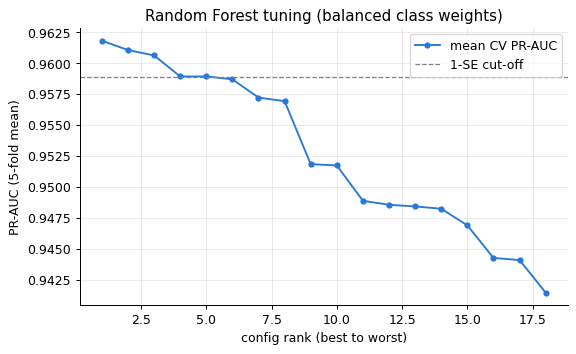

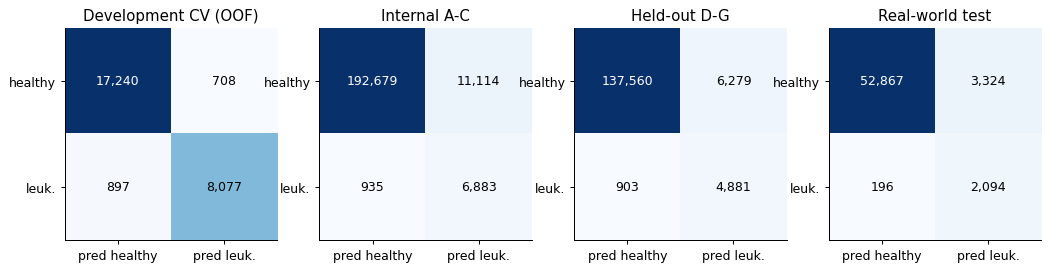

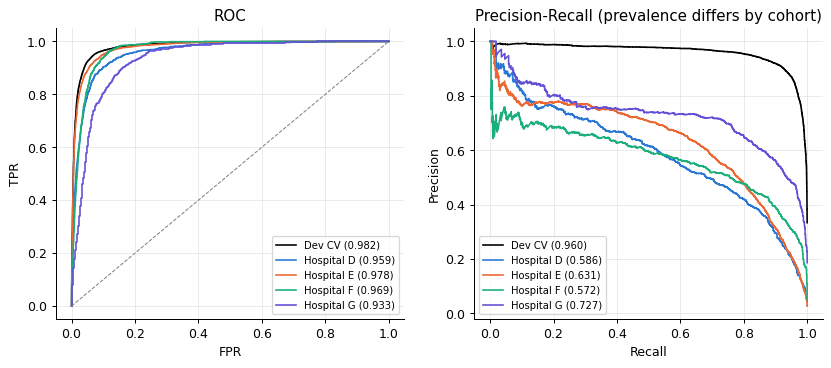

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(tuning) + 1), tuning["PR_AUC"], "o-", color=C_HC, ms=4, label="mean CV PR-AUC")
ax.axhline(cut, color="grey", ls="--", lw=1, label="1-SE cut-off")
ax.set_xlabel("config rank (best to worst)"); ax.set_ylabel("PR-AUC (5-fold mean)")
ax.set_title("Random Forest tuning (balanced class weights)"); ax.legend()
savefig("RF_tuning_curve")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
panels = [("Development CV (OOF)", y_dev, final_oof)]
for lab, mask in [("Internal A-C", held["cohort"] == "internal_validation"),
                  ("Held-out D-G", held["cohort"] == "external_validation"),
                  ("Real-world test", held["cohort"] == "real_world_test")]:
    panels.append((lab, held.loc[mask, "y"], held.loc[mask, "p"]))
for ax, (lab, yy, pp) in zip(axes, panels):
    cm = confusion_matrix(yy, (pp >= THR).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["pred healthy", "pred leuk."]); ax.set_yticks([0, 1], ["healthy", "leuk."])
    ax.set_title(lab); ax.grid(False)
savefig("RF_confusion_matrices")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for lab, yy, pp, c in [("Dev CV", y_dev, final_oof, "black")] + [
        (f"Hospital {s}", held.loc[(held["cohort"] == "external_validation") & (held["site"] == s), "y"],
         held.loc[(held["cohort"] == "external_validation") & (held["site"] == s), "p"], col)
        for s, col in zip("DEFG", ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"])]:
    fpr, tpr, _ = roc_curve(yy, pp); ax1.plot(fpr, tpr, color=c, lw=1.3, label=f"{lab} ({roc_auc_score(yy, pp):.3f})")
    pr, rc, _ = precision_recall_curve(yy, pp); ax2.plot(rc, pr, color=c, lw=1.3, label=f"{lab} ({average_precision_score(yy, pp):.3f})")
ax1.plot([0, 1], [0, 1], "--", color="grey", lw=0.8); ax1.set_xlabel("FPR"); ax1.set_ylabel("TPR"); ax1.set_title("ROC"); ax1.legend(fontsize=8)
ax2.set_xlabel("Recall"); ax2.set_ylabel("Precision"); ax2.set_title("Precision-Recall (prevalence differs by cohort)"); ax2.legend(fontsize=8)
savefig("RF_roc_pr_by_hospital")

## 9. Feature importance

- **Impurity (Gini)** from the final model: fast, but biased toward continuous features with many split points.
- **Permutation** on a 20,000-record held-out sample (D-G): drop in PR-AUC when one feature is shuffled. This is the more honest ranking because it measures held-out use.

baseline PR-AUC on the 20,000-record sample: 0.6315


,feature,PR_AUC_drop_mean,PR_AUC_drop_sd
40,WBC-N,0.050737,0.001611
41,TNC-N,0.039181,0.006549
46,NEUT#&,0.038493,0.000613
8,WBC,0.037808,0.002203
24,NEUT#,0.036754,0.000552
45,TNC-D,0.031555,0.001278
39,TNC,0.031256,0.000486
47,NEUT%&,0.030382,0.013432
44,WBC-D,0.027538,0.005731
15,PLT,0.025680,0.002342


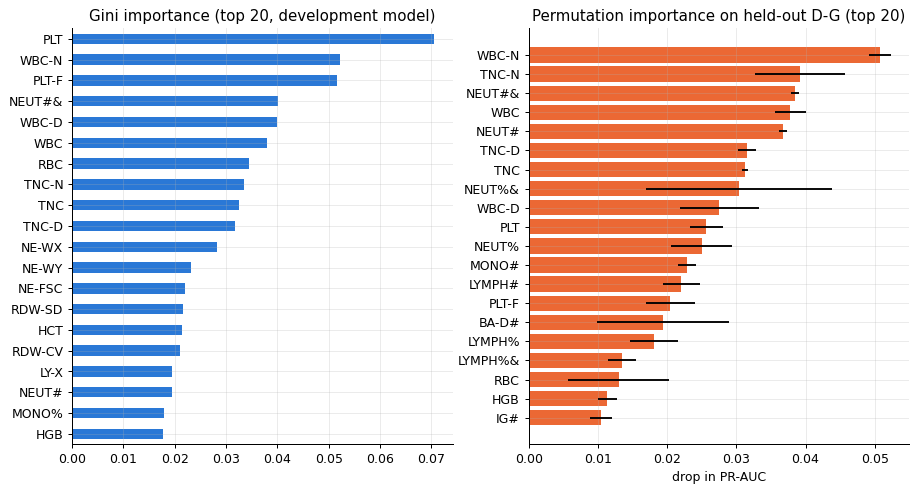

In [10]:
imp = final_model.feature_importance().sort_values(ascending=False)
imp.rename("gini_importance").to_csv(TAB_DIR / "RF_gini_importance.csv")

ext = held[held["cohort"] == "external_validation"].sample(n=20000, random_state=SEED)
base_pr = average_precision_score(ext["y"], final_model.predict_proba(ext[FEATURES])[:, 1])
rng = np.random.default_rng(SEED)
perm_rows = []
for f in FEATURES:
    drops = []
    for _ in range(2):
        Xp = ext[FEATURES].copy()
        Xp[f] = rng.permutation(Xp[f].to_numpy())
        drops.append(base_pr - average_precision_score(ext["y"], final_model.predict_proba(Xp)[:, 1]))
    perm_rows.append({"feature": f, "PR_AUC_drop_mean": np.mean(drops), "PR_AUC_drop_sd": np.std(drops, ddof=1)})
perm = pd.DataFrame(perm_rows).sort_values("PR_AUC_drop_mean", ascending=False)
perm.to_csv(TAB_DIR / "RF_permutation_importance_external.csv", index=False)
print(f"baseline PR-AUC on the 20,000-record sample: {base_pr:.4f}")
display(perm.head(15))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
imp.head(20)[::-1].plot.barh(ax=axes[0], color=C_HC); axes[0].set_title("Gini importance (top 20, development model)")
top_p = perm.head(20).iloc[::-1]
axes[1].barh(top_p["feature"], top_p["PR_AUC_drop_mean"], xerr=top_p["PR_AUC_drop_sd"], color=C_LK)
axes[1].set_title("Permutation importance on held-out D-G (top 20)"); axes[1].set_xlabel("drop in PR-AUC")
savefig("RF_feature_importance")

## 10. Summary

In [11]:
print(f"Selected: {TUNE_PARAMS}, imbalance = {IMBALANCE}, threshold = {THR:.4f}, n_trees = {N_TREES}")
print(f"Development CV   PR-AUC {fold_tab.loc[fold_tab['fold']=='mean','PR_AUC'].item():.4f}  ROC-AUC {fold_tab.loc[fold_tab['fold']=='mean','ROC_AUC'].item():.4f}")
ex = results[results["cohort"] == "external_validation"]
print("Held-out D-G pooled  " + "  ".join(f"{c} {v:.4f}" for c, v in ex[ex["site"] == "pooled"][["recall","specificity","ROC_AUC","PR_AUC"]].iloc[0].items()))

Selected: {'max_depth': 16, 'min_samples_leaf': 1, 'max_features': 'sqrt'}, imbalance = balanced, threshold = 0.5278, n_trees = 300
Development CV   PR-AUC 0.9606  ROC-AUC 0.9816
Held-out D-G pooled  recall 0.8439  specificity 0.9563  ROC_AUC 0.9720  PR_AUC 0.6189
